# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Buhangin, Ahrystan Deniz
- _Student No._: 2024-07766
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="Figures/minimization.png" alt="Minimization" width=45%>


The upper row contains graphs for functions phi(x) and f(x) along with markers denoted by "x"'s which indicate the minima and maxima of each function. The bottow row contains plots for the analytical derivatives of phi(x) and f(x). The zeroes of the derivative functions are observed to coincide with the points at which a minima or maxima were found.


### Report discussion

Although convergence is still likely, using a value outside of the golden ratio will cause the algorithm to require more iterations due to the interval shrinking over succeeding iterations. 

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

phi(x) has local minima at x = 0.7499999810705207 , 3.99999998065321
phi(x) has a local maximum at x = 1.9999999831570725
f(x) has a local minimum at x= -0.6798620124829506 , 4.103324881059825
f(x) has a local maximum at x= 2.000000022047679


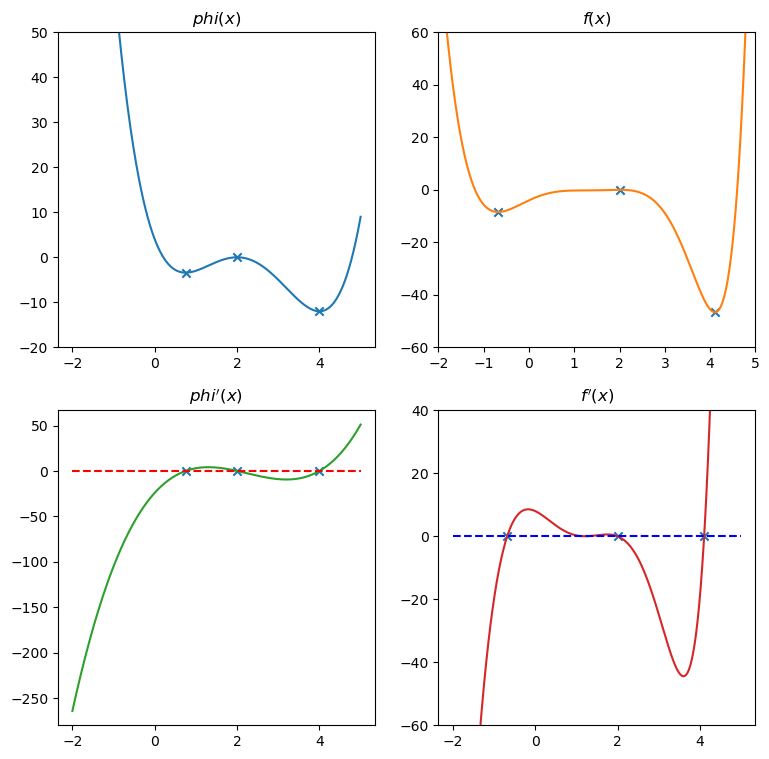

In [2]:
# Define functions phi(x) and f(x), along with their analytical derivatives

def phi(x):
    return (x**4) - 9*(x**3) + 25*(x**2) - 24*x + 4

def phi_p(x):
    return 4*(x**3) - 27*(x**2) + 50*x - 24

def f(x):
    return -(x**5) + 4*(x**4) - 4*(x**3) + (x**2)*(np.exp(x)) - 2*(x**2) - 4*x*(np.exp(x)) + 8*x + 4*(np.exp(x)) - 8

def f_p(x):
    return -5*(x**4) + 16*(x**3) - 12*(x**2) + (x**2)*(np.exp(x)) + 2*x*(np.exp(x)) - 4*x - 4*x*(np.exp(x)) - 4*(np.exp(x)) + 8 + 4*(np.exp(x))

# Define a function to carry out the golden section search
# sign paramter is used to allow flexibility in taking either minimaor maxima

def gss(f, x_0, x_1, sign=1, kmax=200, tol=1e-8):
    phi_var = 0.5*(1+math.sqrt(5))
    for k in range(1, kmax):
        x_2 = x_0 + (x_1 - x_0) / (phi_var + 1)
        x_3 = x_0 + phi_var*(x_1 - x_0) / (phi_var + 1)

        if sign*f(x_3) < sign*f(x_2):
            x_0 = x_2
        else:
            x_1 = x_3

        x_new = (x_0 + x_1) / 2
        diff = abs(x_1 - x_0)

        if abs(diff) < tol:
            break
    else:
        x_new = None
    return x_new

# Obtain the minima and maxima of each function

phi_min1, phi_min2 = gss(phi, 0, 1), gss(phi, 3, 4)
phi_max1 = gss(phi, 1, 3, -1)
f_min1, f_min2 = gss(f, -2, 0), gss(f, 3, 5)
f_max1 = gss(f, 2, 3, -1)
print("phi(x) has local minima at x =", phi_min1, ",", phi_min2)
print("phi(x) has a local maximum at x =", phi_max1)
print("f(x) has a local minimum at x=", f_min1,",", f_min2)
print("f(x) has a local maximum at x=", f_max1)

# Graph both functions, their derivatives, and the calculated extrema

x = np.linspace(-2, 5, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))
axs[0, 0].plot(x, phi(x))
axs[0, 0].set_ylim(-20, 50)
axs[0, 0].set_title("$phi(x)$")
axs[0, 0].scatter([phi_min1, phi_min2, phi_max1], [phi(phi_min1), phi(phi_min2), phi(phi_max1)], marker='x')
axs[0, 1].plot(x, f(x), 'tab:orange')
axs[0, 1].set_xlim(-2, 5)
axs[0, 1].set_ylim(-60, 60)
axs[0, 1].set_title('$f(x)$')
axs[0, 1].scatter([f_min1, f_min2, f_max1], [f(f_min1), f(f_min2), f(f_max1)], marker='x')
axs[1, 0].plot(x, phi_p(x), 'tab:green')
axs[1, 0].plot(x, f(x) - f(x), 'r--')
axs[1, 0].set_title("$phi'(x)$")
axs[1, 0].scatter([phi_min1, phi_min2, phi_max1], [phi_p(phi_min1), phi_p(phi_min2), phi_p(phi_max1)], marker='x')
axs[1, 1].plot(x, f_p(x), 'tab:red')
axs[1, 1].set_ylim(-60,40)
axs[1, 1].plot(x,f(x) - f(x), 'b--')
axs[1, 1].set_title("$f'(x)$")
axs[1, 1].scatter([f_min1, f_min2, f_max1], [f_p(f_min1), f_p(f_min2), f_p(f_max1)], marker='x')
plt.savefig('/home/jovyan/Buhangin_AP155/AP155_TX1_1sAY2627/ahrystanB/Figures/minimization.png')
fig.show()

#### Problem 1 code summary

The above code defines two functions phi(x) and f(x), along with with a golden section search (gss) function which takes in another function, an interval bounded by x_0 and x_1, and a parameter $sign$ which helps inverse a function to allow us to produce an estimate for a both minima and maxima. The succeeding code simply graphs the functions and their derivative, along with the calculated maxima and minima.

---